### Tackle Noise with Error Correction

In [1]:
# Install the required libraries
%pip install qiskit qiskit-aer matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# Import the necessary libraries
from qiskit import QuantumCircuit,QuantumRegister,ClassicalRegister
from qiskit_aer import AerSimulator
import matplotlib.pyplot as plt

In [4]:
# Create the error-correcting circuit
def create_error_correction_circuit(logical_bit,error_qubit):
    # Three data quibits and two syndrome ancillas
    data = QuantumRegister(3, 'data')
    ancilla = QuantumRegister(2, 'ancilla')

    syndrome = ClassicalRegister(2, 'syndrome')
    result = ClassicalRegister(3, 'result')

    qc = QuantumCircuit(data, ancilla, syndrome, result)

    # Step1:Encode the logical bit
    if logical_bit==1:
        qc.x(data[0])
        qc.x(data[1])
        qc.x(data[2])

    qc.barrier()

    # Step 2: Introduce an bit flip error
    qc.x(data[error_qubit])

    qc.barrier()

    # Step 3:Measure parity to identify the error
    qc.cx(data[0], ancilla[0])
    qc.cx(data[1], ancilla[0])

    qc.cx(data[1], ancilla[1])
    qc.cx(data[2], ancilla[1])

    qc.measure(ancilla[0], syndrome[0])
    qc.measure(ancilla[1], syndrome[1])
    qc.barrier()

    # Step4:Correct the error using the syndrome
    # Syndrome 01(integer1):qubit 0 flipped
    with qc.if_test((syndrome, 1)):
        qc.x(data[0])

    # Syndrome 11(integer3):qubit 1 flipped
    with qc.if_test((syndrome, 3)):
        qc.x(data[1])

    # Syndrome 10(integer2):qubit 2 flipped
    with qc.if_test((syndrome, 2)):
        qc.x(data[2])

    qc.barrier()

    # Step5:Measure the data qubits to get the result
    qc.measure(data, result)

    return qc


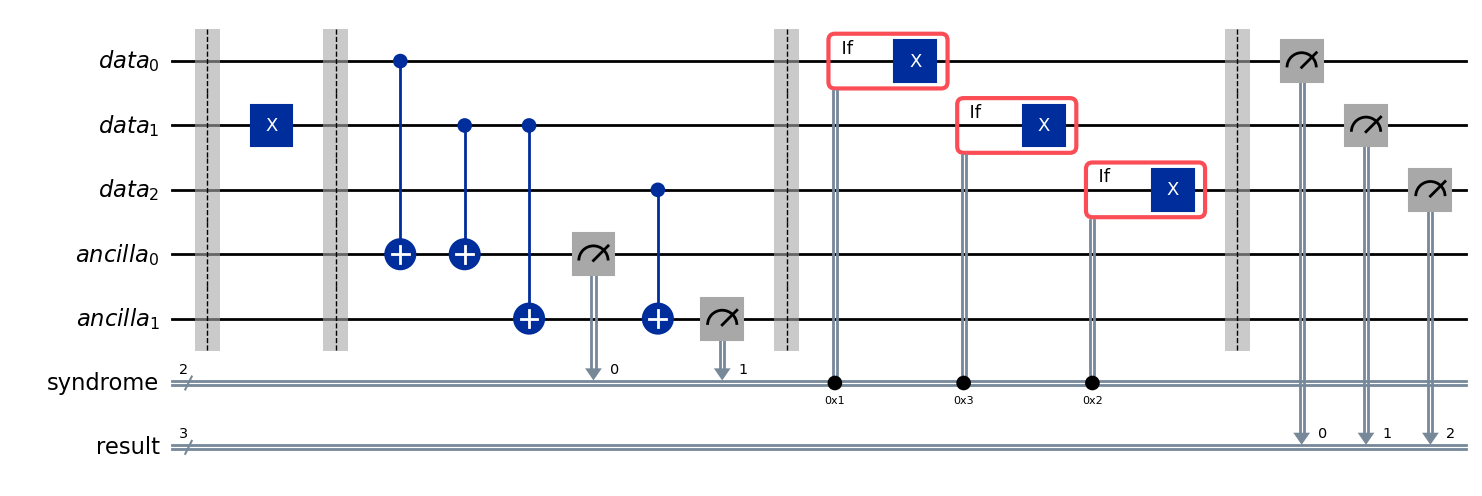

In [5]:
# Display the quantum circuit
qc = create_error_correction_circuit(logical_bit=0,error_qubit=1)
qc.draw("mpl")

In [6]:
# Run the experiment 
simulator = AerSimulator()

job = simulator.run(qc, shots=1024)
result = job.result()
counts = result.get_counts()

print("Measurement Results:")
print(counts)

Measurement Results:
{'000 11': 1024}


In [7]:
# Test all the three possible single-qubit erros
logical_bit = 0
error_results = {}

for error_qubit in range(3):
    test_circuit = create_error_correction_circuit(
        logical_bit=logical_bit, 
        error_qubit=error_qubit
        )
    
    job = simulator.run(test_circuit, shots=1024)
    counts = job.result().get_counts()
    error_results[error_qubit] = counts

    print(f"Error on qubit {error_qubit}: {counts}")

Error on qubit 0: {'000 01': 1024}
Error on qubit 1: {'000 11': 1024}
Error on qubit 2: {'000 10': 1024}


In [8]:
# Step 7:Test logical 1 as well(OPTIONAL)

logical_bit = 1

for error_qubit in range(3):
    test_circuit = create_error_correction_circuit(
        logical_bit=logical_bit,
        error_qubit=error_qubit
    )

    job = simulator.run(test_circuit, shots=1024)
    counts = job.result().get_counts()

    print(f"\nLogical bit 1, error on qubit {error_qubit}:")
    print(counts)


Logical bit 1, error on qubit 0:
{'111 01': 1024}

Logical bit 1, error on qubit 1:
{'111 11': 1024}

Logical bit 1, error on qubit 2:
{'111 10': 1024}


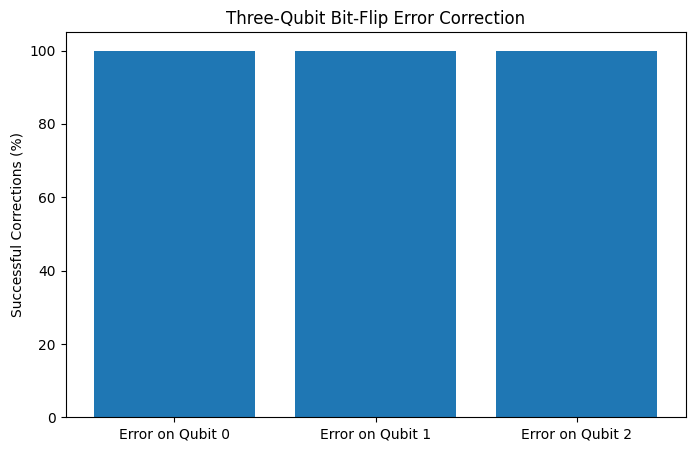

Success rates: [100.0, 100.0, 100.0]


In [9]:
# Visualise the results
labels = ["Error on Qubit 0", "Error on Qubit 1", "Error on Qubit 2"]
success_rates = []

for error_qubit in range(3):
    counts = error_results[error_qubit]
    total_shots = sum(counts.values())

    # The data register is the leftmost group in the displayed bit string.
    successful_shots = sum(
        count for bitstring, count in counts.items()
        if bitstring.split()[0] == "000"
    )

    success_rates.append(100 * successful_shots / total_shots)

plt.figure(figsize=(8, 5))
plt.bar(labels, success_rates)
plt.ylim(0, 105)
plt.ylabel("Successful Corrections (%)")
plt.title("Three-Qubit Bit-Flip Error Correction")
plt.show()

print("Success rates:", success_rates)